In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\HP\Downloads\Applicant.csv")

In [3]:
# Checkng data
print("Shape of dataset :",df.shape)
print("\nInformation of dataset :\n")
print(df.info())
print("\nNumerical column description of dataset :\n",df.describe())

Shape of dataset : (100000, 13)

Information of dataset :

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype
---  ------                       --------------   -----
 0   Applicant_ID                 100000 non-null  int64
 1   Annual_Income                100000 non-null  int64
 2   Applicant_Age                100000 non-null  int64
 3   Work_Experience              100000 non-null  int64
 4   Marital_Status               100000 non-null  str  
 5   House_Ownership              100000 non-null  str  
 6   Vehicle_Ownership(car)       100000 non-null  str  
 7   Occupation                   100000 non-null  str  
 8   Residence_City               100000 non-null  str  
 9   Residence_State              100000 non-null  str  
 10  Years_in_Current_Employment  100000 non-null  int64
 11  Years_in_Current_Residence   100000 non-null  int64
 12  Loan_Default_Risk            100000 non

In [4]:
# Check null and duplicated values and chech data types
print("Null values in dataset :")
print(df.isnull().sum())
print("\n Duplicate values in dataset :")
print(df.duplicated().sum())
print("\nDatatypes of dataset :")
print(df.dtypes)

Null values in dataset :
Applicant_ID                   0
Annual_Income                  0
Applicant_Age                  0
Work_Experience                0
Marital_Status                 0
House_Ownership                0
Vehicle_Ownership(car)         0
Occupation                     0
Residence_City                 0
Residence_State                0
Years_in_Current_Employment    0
Years_in_Current_Residence     0
Loan_Default_Risk              0
dtype: int64

 Duplicate values in dataset :
0

Datatypes of dataset :
Applicant_ID                   int64
Annual_Income                  int64
Applicant_Age                  int64
Work_Experience                int64
Marital_Status                   str
House_Ownership                  str
Vehicle_Ownership(car)           str
Occupation                       str
Residence_City                   str
Residence_State                  str
Years_in_Current_Employment    int64
Years_in_Current_Residence     int64
Loan_Default_Risk              

In [5]:
df.columns.tolist()

['Applicant_ID',
 'Annual_Income',
 'Applicant_Age',
 'Work_Experience',
 'Marital_Status',
 'House_Ownership',
 'Vehicle_Ownership(car)',
 'Occupation',
 'Residence_City',
 'Residence_State',
 'Years_in_Current_Employment',
 'Years_in_Current_Residence',
 'Loan_Default_Risk']

In [6]:
# Check Loan Default Risk percentage
ldr = df['Loan_Default_Risk'].value_counts()/len(df)*100
print(ldr)
print(f"\nNot High Risk labeled : {ldr[0]} %")
print(f"High Risk labeled : {ldr[1]} %")

Loan_Default_Risk
0    87.003
1    12.997
Name: count, dtype: float64

Not High Risk labeled : 87.003 %
High Risk labeled : 12.997 %


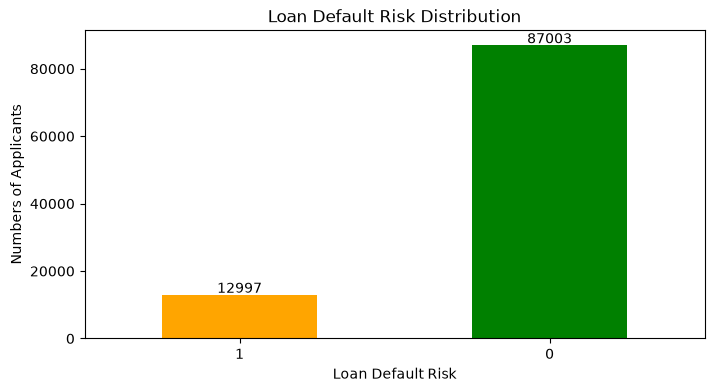

In [7]:
# Visualisation of loan deafault risk
plt.figure(figsize=(8,4))
fig = df['Loan_Default_Risk'].value_counts().sort_index(ascending=False).plot(kind="bar",color=["Orange","Green"])
plt.title("Loan Default Risk Distribution")
plt.xlabel("Loan Default Risk")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=-1)
plt.show()

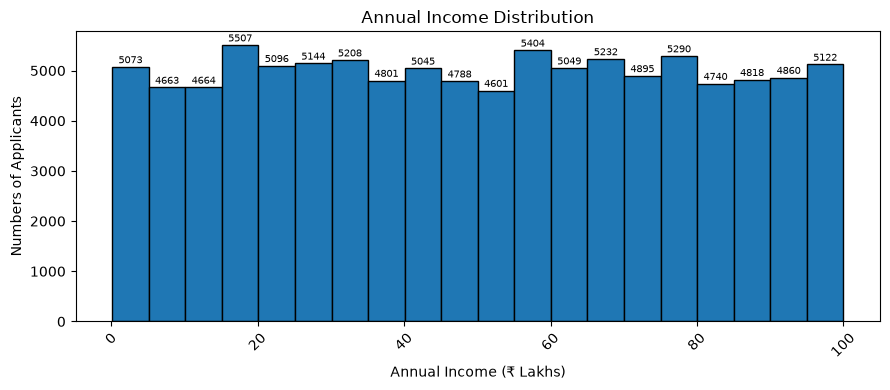

In [8]:
# Analyze Annual Income
plt.figure(figsize=(9,4))
n, bins, patches = plt.hist(df["Annual_Income"]/100000, bins = 20, edgecolor="Black")

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (₹ Lakhs)")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=45)
plt.bar_label(patches, padding=1, fmt="%.0f", fontsize=7)
plt.tight_layout()
plt.show()

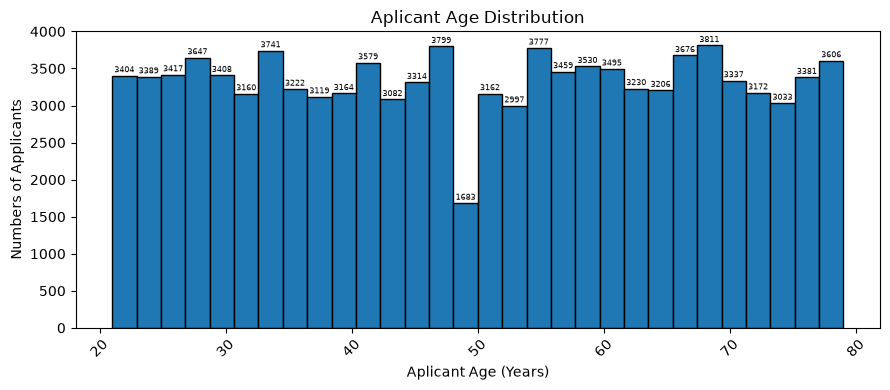

In [9]:
# Analyze the age of aplicant
plt.figure(figsize=(9,4))
n, bins, patches = plt.hist(df["Applicant_Age"], bins = 30, edgecolor="Black")

plt.title("Aplicant Age Distribution")
plt.xlabel("Aplicant Age (Years)")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=45)
plt.bar_label(patches, padding=1, fmt="%.0f", fontsize=6)
plt.tight_layout()
plt.show()

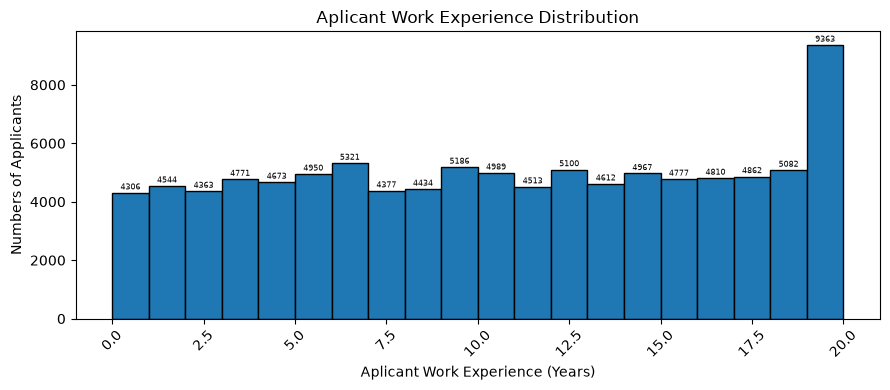

In [10]:
# Analyze the work experience of aplicant
plt.figure(figsize=(9,4))
n, bins, patches = plt.hist(df["Work_Experience"], bins = 20, edgecolor="Black")

plt.title("Aplicant Work Experience Distribution")
plt.xlabel("Aplicant Work Experience (Years)")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=45)
plt.bar_label(patches, padding=1, fmt="%.0f", fontsize=6)
plt.tight_layout()
plt.show()

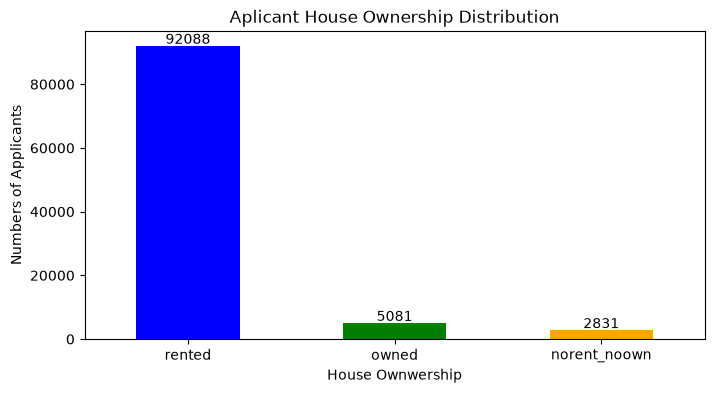

In [11]:
# Check for House Owner or not House_Ownership
plt.figure(figsize=(8,4))
fig = df['House_Ownership'].value_counts().sort_index(ascending=False).plot(kind="bar",color=["Blue","Green","Orange"])
plt.title("Aplicant House Ownership Distribution")
plt.xlabel("House Ownwership")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=-1)
plt.show()

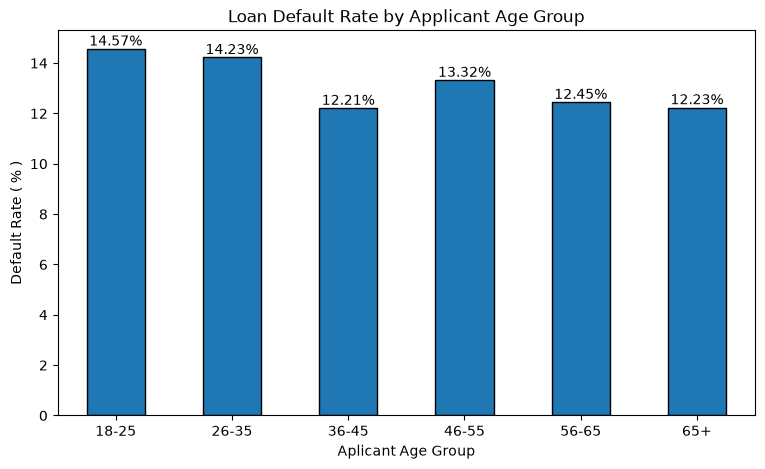

In [12]:
# Check loan default risk percentage by Age groups

# crate age groups
df["Age_Group"] = pd.cut(df["Applicant_Age"],
                         bins = [0,25,35,45,55,65,100],
                         labels = ["18-25","26-35","36-45","46-55","56-65","65+"]
                        )

fig = df.groupby("Age_Group")["Loan_Default_Risk"].mean().mul(100).plot(kind="bar",figsize=(9,5),edgecolor="Black")

plt.title("Loan Default Rate by Applicant Age Group")
plt.xlabel("Aplicant Age Group")
plt.ylabel("Default Rate ( % )")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=0,fmt="%.2f%%")
plt.show()

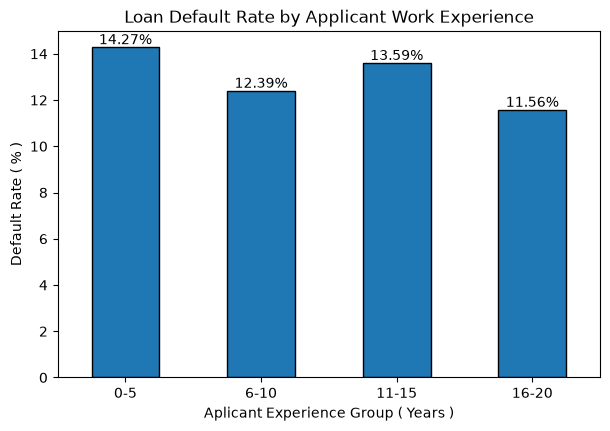

In [13]:
# Check loan default risk percentage by work experience

# crate experience groups
df["Exp_Group"] = pd.cut(df["Work_Experience"],
                         bins = [-1,5,10,15,20,50],
                         labels = ["0-5","6-10","11-15","16-20","20+"]
                        )

fig = df.groupby("Exp_Group")["Loan_Default_Risk"].mean().mul(100).plot(kind="bar",figsize=(7,4.5),edgecolor="Black")

plt.title("Loan Default Rate by Applicant Work Experience")
plt.xlabel("Aplicant Experience Group ( Years )")
plt.ylabel("Default Rate ( % )")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=0,fmt="%.2f%%")
plt.show()

In [14]:
print(df.dtypes)

Applicant_ID                      int64
Annual_Income                     int64
Applicant_Age                     int64
Work_Experience                   int64
Marital_Status                      str
House_Ownership                     str
Vehicle_Ownership(car)              str
Occupation                          str
Residence_City                      str
Residence_State                     str
Years_in_Current_Employment       int64
Years_in_Current_Residence        int64
Loan_Default_Risk                 int64
Age_Group                      category
Exp_Group                      category
dtype: object


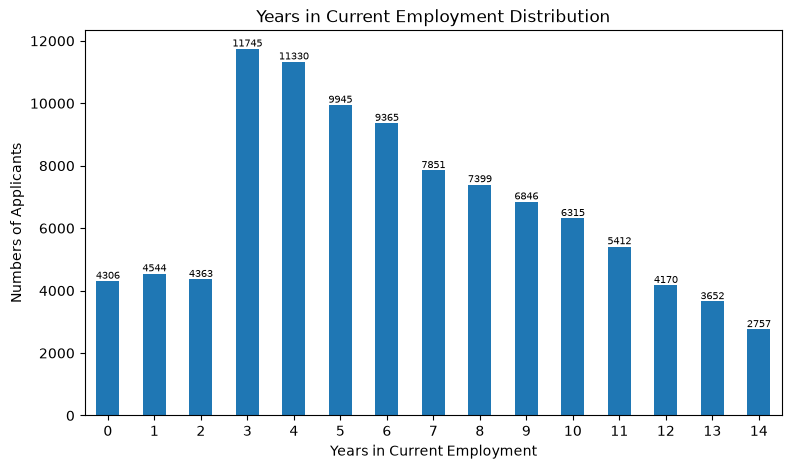

In [15]:
# Visualisation of current employmet distribution
plt.figure(figsize=(9,5))
fig = df['Years_in_Current_Employment'].value_counts().sort_index().plot(kind="bar")
plt.title("Years in Current Employment Distribution")
plt.xlabel("Years in Current Employment")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=0,fontsize=7)
plt.show()

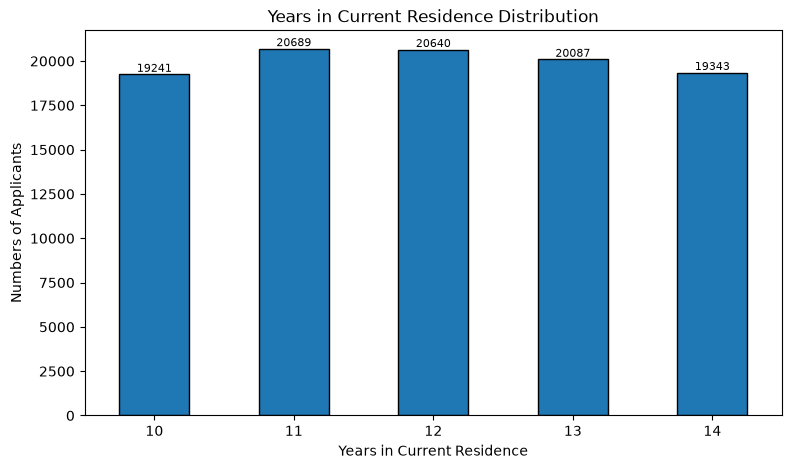

In [16]:
# Visualisation of Years of current residencial
plt.figure(figsize=(9,5))
fig = df['Years_in_Current_Residence'].value_counts().sort_index().plot(kind="bar",edgecolor="Black")
plt.title("Years in Current Residence Distribution")
plt.xlabel("Years in Current Residence")
plt.ylabel("Numbers of Applicants")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=0,fontsize=8)
plt.show()

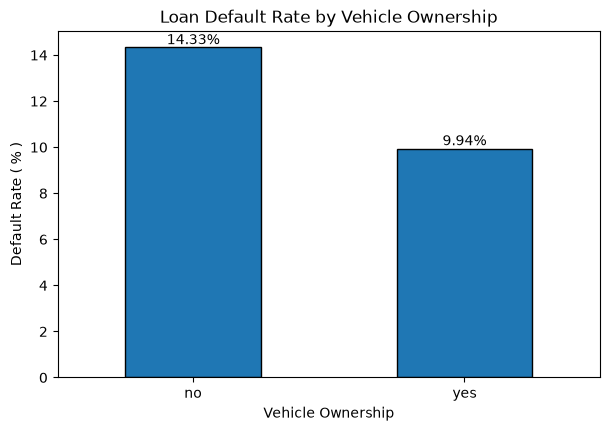

In [17]:
#  Visualisation of Categorical Feature analysis by Vehicle Ownership

fig = df.groupby("Vehicle_Ownership(car)")["Loan_Default_Risk"].mean().mul(100).plot(kind="bar",figsize=(7,4.5),edgecolor="Black")

plt.title("Loan Default Rate by Vehicle Ownership")
plt.xlabel("Vehicle Ownership")
plt.ylabel("Default Rate ( % )")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=0,fmt="%.2f%%")
plt.show()

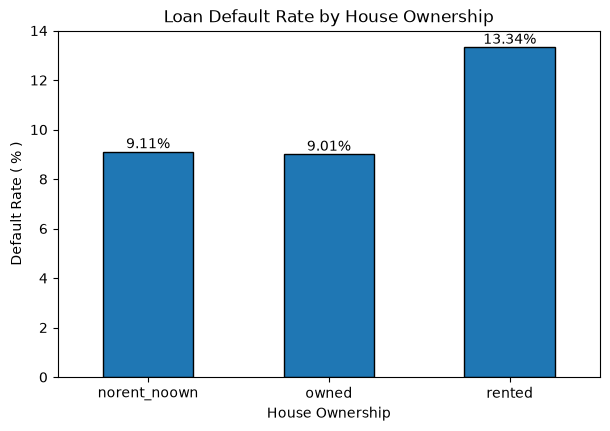

In [18]:
#  Visualisation of Categorical Feature analysis by House Ownership

fig = df.groupby("House_Ownership")["Loan_Default_Risk"].mean().mul(100).plot(kind="bar",figsize=(7,4.5),edgecolor="Black")

plt.title("Loan Default Rate by House Ownership")
plt.xlabel("House Ownership")
plt.ylabel("Default Rate ( % )")
plt.xticks(rotation=0)
fig.bar_label(fig.containers[0],padding=0,fmt="%.2f%%")
plt.show()

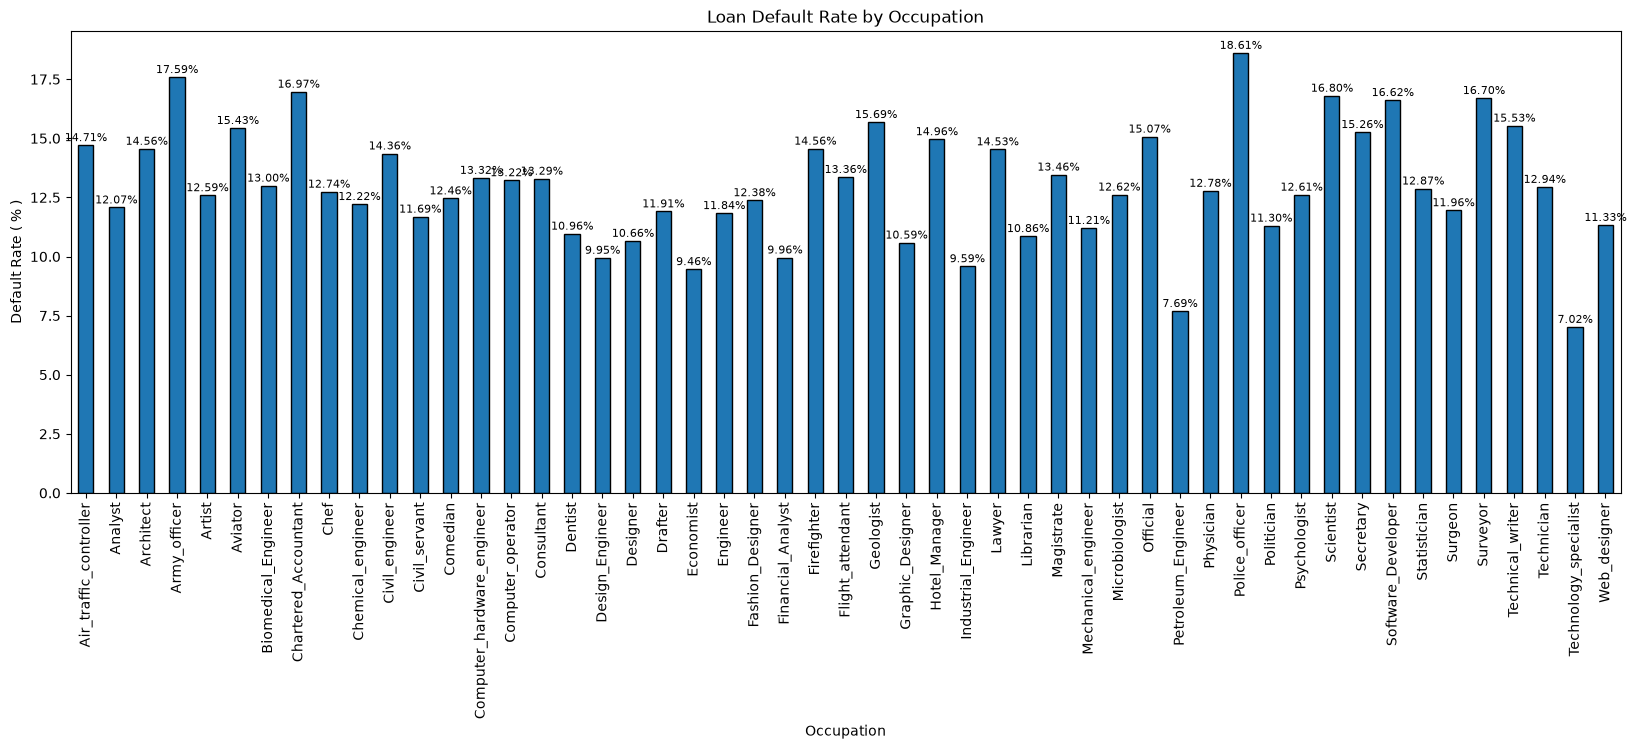

In [19]:
#  Visualisation of Occupation vs Dafault load risk
 
fig = df.groupby("Occupation")["Loan_Default_Risk"].mean().mul(100).plot(kind="bar",figsize=(20,6),edgecolor="Black")

plt.title("Loan Default Rate by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Default Rate ( % )")
plt.xticks(rotation=90)
fig.bar_label(fig.containers[0],padding=1,fmt="%.2f%%",fontsize=8)
plt.show()

# Build Classification Model

In [20]:
df.columns

Index(['Applicant_ID', 'Annual_Income', 'Applicant_Age', 'Work_Experience',
       'Marital_Status', 'House_Ownership', 'Vehicle_Ownership(car)',
       'Occupation', 'Residence_City', 'Residence_State',
       'Years_in_Current_Employment', 'Years_in_Current_Residence',
       'Loan_Default_Risk', 'Age_Group', 'Exp_Group'],
      dtype='str')

In [21]:
# 1. Select Input features
X = df.drop(columns=["Applicant_ID", "Loan_Default_Risk", "Age_Group", "Exp_Group"])

# Select Target Feature
y = df["Loan_Default_Risk"]

print("Input Feature X Shape : ",X.shape)
print("\nTarget Feature y Shape : ",y.shape)

Input Feature X Shape :  (100000, 11)

Target Feature y Shape :  (100000,)


In [22]:
# 2. Train test split the data 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print("Training data : ",X_train.shape)
print("Testing data : ",X_test.shape)

Training data :  (80000, 11)
Testing data :  (20000, 11)


In [24]:
# Importing Libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix


In [28]:
# Identify numerical and categorical columns
cat_cols = X.select_dtypes(exclude="number").columns
num_cols = X.select_dtypes(include="number").columns

print(cat_cols)
print(num_cols)

Index(['Marital_Status', 'House_Ownership', 'Vehicle_Ownership(car)',
       'Occupation', 'Residence_City', 'Residence_State'],
      dtype='str')
Index(['Annual_Income', 'Applicant_Age', 'Work_Experience',
       'Years_in_Current_Employment', 'Years_in_Current_Residence'],
      dtype='str')


In [62]:
# Preprocessor and build model and Train model
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
    ])
                                
                               

# Logistic Model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000,class_weight="balanced"))
     ])

# Train model
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Annual_Income','Applicant_Age','Work_Experience',...,'Residence_State', 'Years_in_Current_Employment','Years_in_Current_Residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (def

In [63]:
# Predictiction
y_pred = model.predict(X_test)

In [64]:
print("Actual values:")
print(y_test.value_counts())

print("\nPredicted values:")
print(pd.Series(y_pred).value_counts())

Actual values:
Loan_Default_Risk
0    17401
1     2599
Name: count, dtype: int64

Predicted values:
0    11319
1     8681
Name: count, dtype: int64


In [65]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[10389  7012]
 [  930  1669]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.60      0.72     17401
           1       0.19      0.64      0.30      2599

    accuracy                           0.60     20000
   macro avg       0.56      0.62      0.51     20000
weighted avg       0.82      0.60      0.67     20000



In [66]:
# Preprocessor and build model and Train model
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
    ])
                                
                               

# Random Forest Model pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100,random_state=42,class_weight="balanced",n_jobs=-1))
     ])

# Train model
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Annual_Income','Applicant_Age','Work_Experience',...,'Residence_State', 'Years_in_Current_Employment','Years_in_Current_Residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (def

In [73]:
y_pred_rf = rf_model.predict(X_test)
y_train_rf = rf_model.predict(X_train)
print("Actual values:")
print(y_test.value_counts())

print("\nPredicted values:")
print(pd.Series(y_pred_rf).value_counts())

Actual values:
Loan_Default_Risk
0    17401
1     2599
Name: count, dtype: int64

Predicted values:
0    16068
1     3932
Name: count, dtype: int64


In [74]:
# Check all metrics
print("Training Data Accuracy : ",accuracy_score(y_train, y_train_rf))
print("\nConfusion Matrix :\n",confusion_matrix(y_test,y_pred_rf))
print("\nTest Data Accuracy : ",accuracy_score(y_test,y_pred_rf))
print("\nTest Data Precision Score : ",precision_score(y_test,y_pred_rf))
print("\nTest Data Recall Score : ",recall_score(y_test,y_pred_rf))
print("\nTest Data F1 Score : ",f1_score(y_test,y_pred_rf))
print("\nTest Data roc auc score : ",roc_auc_score(y_test,y_pred_rf))
print("\nTest Data Classification Report : \n",classification_report(y_test,y_pred_rf))

Training Data Accuracy :  0.9334375

Confusion Matrix :
 [[16057  1344]
 [   11  2588]]

Test Data Accuracy :  0.93225

Test Data Precision Score :  0.6581892166836215

Test Data Recall Score :  0.9957676029242016

Test Data F1 Score :  0.7925279436533456

Test Data roc auc score :  0.9592653312592389

Test Data Classification Report : 
               precision    recall  f1-score   support

           0       1.00      0.92      0.96     17401
           1       0.66      1.00      0.79      2599

    accuracy                           0.93     20000
   macro avg       0.83      0.96      0.88     20000
weighted avg       0.95      0.93      0.94     20000



In [75]:
# Save the Model 
import joblib

joblib.dump(rf_model, "loan_default_risk_random_forest.pkl")
print("Model Saved Successfully")

Model Saved Successfully


In [106]:
# Prediction using our model
applicant = pd.DataFrame([{
    "Annual_Income": 500000,
    "Applicant_Age": 22,
    "Work_Experience": 4,
    "Marital_Status": "Married",
    "House_Ownership": "Owned",
    "Vehicle_Ownership(car)": "No",
    "Occupation": "Engineer",
    "Residence_City": "Pune",
    "Residence_State": "Maharashtra",
    "Years_in_Current_Employment": 2,
    "Years_in_Current_Residence": 5
}])

# Predict loan deafault risk
prediction = rf_model.predict(applicant)[0]
probability = rf_model.predict_proba(applicant)[0]

print("Default Risk Probability:", round(probability[1] * 100, 2), "%")

if probability[1] >= 0.15:
    print("Result: Default Risk to approve loan")
else:
    print("Result: Not Default Risk to approve loan")



Default Risk Probability: 18.23 %
Result: Default Risk to approve loan


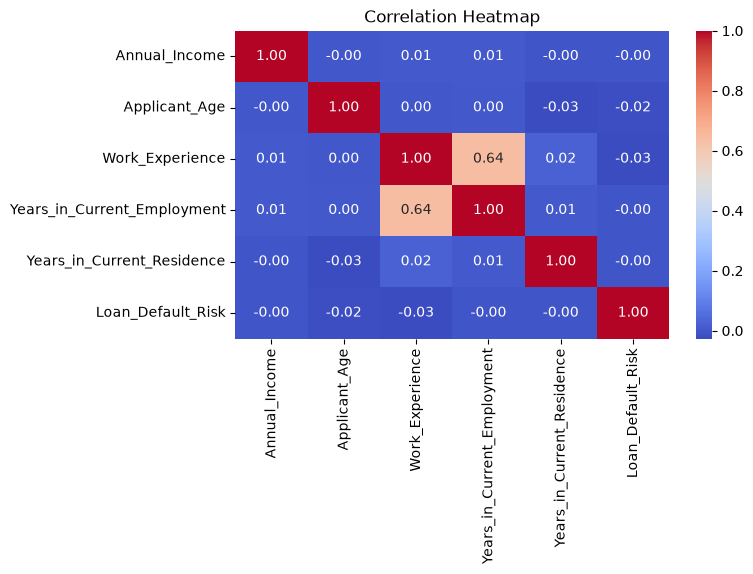

In [112]:
# Corrlation chart
num_df = df.select_dtypes(include="number").drop(columns=["Applicant_ID"])

corr = num_df.corr()

plt.figure(figsize=(7,4))
sns.heatmap(corr, annot=True, cmap = "coolwarm", fmt = ".2f")
plt.title("Correlation Heatmap")
plt.show()

# Build Regression Model


# 1. Linear Regression Model

In [113]:
df.columns

Index(['Applicant_ID', 'Annual_Income', 'Applicant_Age', 'Work_Experience',
       'Marital_Status', 'House_Ownership', 'Vehicle_Ownership(car)',
       'Occupation', 'Residence_City', 'Residence_State',
       'Years_in_Current_Employment', 'Years_in_Current_Residence',
       'Loan_Default_Risk', 'Age_Group', 'Exp_Group'],
      dtype='str')

In [196]:
# Input features 
X = df.drop(columns=["Applicant_ID", "Annual_Income", "Age_Group", "Exp_Group", "Loan_Default_Risk"])

# Target Feature
y = df["Annual_Income"]

print("Input Feature Shape : ",X.shape)
print("Target Feature Shape : ",y.shape)

Input Feature Shape :  (100000, 10)
Target Feature Shape :  (100000,)


In [197]:
# import libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 

In [198]:
# Train test split 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print("X Train Shape : ",X_train.shape)
print("X Test Shape : ",X_test.shape)
print("y Train Shape : ",y_train.shape)
print("y Test Shape : ",y_test.shape)

X Train Shape :  (80000, 10)
X Test Shape :  (20000, 10)
y Train Shape :  (80000,)
y Test Shape :  (20000,)


In [199]:
# Categorical and numerical columns
cat_cols = X.select_dtypes(include=["object","str"]).columns
num_cols = X.select_dtypes(include="number").columns

print(cat_cols)
print(num_cols)


Index(['Marital_Status', 'House_Ownership', 'Vehicle_Ownership(car)',
       'Occupation', 'Residence_City', 'Residence_State'],
      dtype='str')
Index(['Applicant_Age', 'Work_Experience', 'Years_in_Current_Employment',
       'Years_in_Current_Residence'],
      dtype='str')


In [200]:
# Preprocessing
preprocessor = ColumnTransformer ([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

# Pipeline Linear Regression model
lin_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
lin_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Applicant_Age','Work_Experience','Marital_Status',...,'Residence_State', 'Years_in_Current_Employment','Years_in_Current_Residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto

In [201]:
# Model Evaluation
y_pred = lin_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error : ",mae)
print("Mean Squared Error : ",mse)
print("Root Mean Squared Error : ",rmse)
print("R2 Score : ",r2)

Mean Absolute Error :  2402848.442287438
Mean Squared Error :  7834643906327.967
Root Mean Squared Error :  2799043.3912906684
R2 Score :  0.05410786272849255


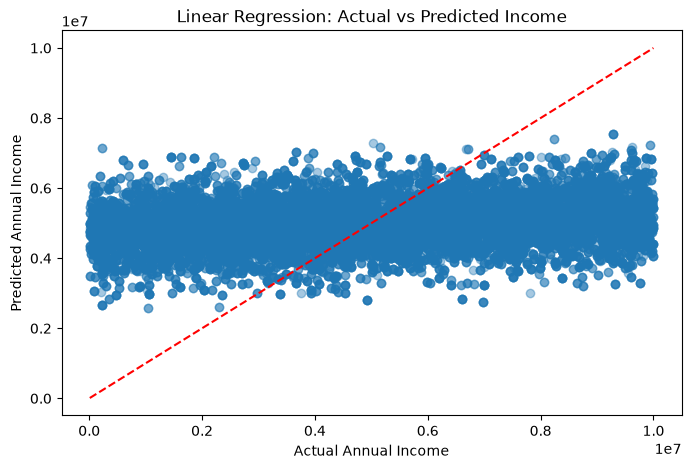

In [202]:
# Linear Regression Actual Vs predicted Income
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],"r--")

plt.xlabel("Actual Annual Income")
plt.ylabel("Predicted Annual Income")
plt.title("Linear Regression: Actual vs Predicted Income")
plt.show()

# 2. Decision Tre Regressor Model 


In [203]:
# Pipeline Linear Regression model
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

# Train the model
tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Applicant_Age','Work_Experience','Marital_Status',...,'Residence_State', 'Years_in_Current_Employment','Years_in_Current_Residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto

In [204]:
# Model Evaluation
y_pred_tree = tree_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_tree)
mse = mean_squared_error(y_test, y_pred_tree)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_tree)

print("Mean Absolute Error : ",mae)
print("Mean Squared Error : ",mse)
print("Root Mean Squared Error : ",rmse)
print("R2 Score : ",r2)

Mean Absolute Error :  1.5882352960761636e-05
Mean Squared Error :  1.3587081940036862e-06
Root Mean Squared Error :  0.0011656363901335982
R2 Score :  1.0


# 3. Random Forest Regression Model

In [205]:
rf_reg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=50,max_depth=15,random_state=42,n_jobs=-1))
])

# Train the model
rf_reg_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Applicant_Age','Work_Experience','Marital_Status',...,'Residence_State', 'Years_in_Current_Employment','Years_in_Current_Residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto

In [206]:
# Model Evaluation
y_pred_rf = rf_reg_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

print("Mean Absolute Error : ",mae)
print("Mean Squared Error : ",mse)
print("Root Mean Squared Error : ",rmse)
print("R2 Score : ",r2)

Mean Absolute Error :  2369020.2237087144
Mean Squared Error :  7639533696089.315
Root Mean Squared Error :  2763970.6395128937
R2 Score :  0.07766390636910636


# 4. Ridge Regression Model

In [207]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=1.0))
])

# Train the model
ridge_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Applicant_Age','Work_Experience','Marital_Status',...,'Residence_State', 'Years_in_Current_Employment','Years_in_Current_Residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto

In [208]:
# Model Evaluation
y_pred_ridge = ridge_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_ridge)
mse = mean_squared_error(y_test, y_pred_ridge)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_ridge)

print("Mean Absolute Error : ",mae)
print("Mean Squared Error : ",mse)
print("Root Mean Squared Error : ",rmse)
print("R2 Score : ",r2)

Mean Absolute Error :  2402955.2910100846
Mean Squared Error :  7834413318255.437
Root Mean Squared Error :  2799002.2004734897
R2 Score :  0.054135702084991966


In [209]:
reg_results = pd.DataFrame({
    "Model": [
        "1. Linear Regression",
        "2. Decision Tree Regression",
        "3. Random Forest",
        "4. Ridge Regression"
    ],
    "Mean Absolute Error": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, y_pred_tree),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_ridge)
    ],
    "Mean Squared Error": [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, y_pred_tree),
        mean_squared_error(y_test, y_pred_rf),
        mean_squared_error(y_test, y_pred_ridge)
    ],
    "Root Mean Squared Error": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred_tree)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge))
    ],
    "R2 Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_pred_tree),
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred_ridge)
    ]
})

print(reg_results.round(4).to_string())


                         Model  Mean Absolute Error  Mean Squared Error  Root Mean Squared Error  R2 Score
0         1. Linear Regression         2.402848e+06        7.834644e+12             2.799043e+06    0.0541
1  2. Decision Tree Regression         0.000000e+00        0.000000e+00             1.200000e-03    1.0000
2             3. Random Forest         2.369020e+06        7.639534e+12             2.763971e+06    0.0777
3          4. Ridge Regression         2.402955e+06        7.834413e+12             2.799002e+06    0.0541


# Build Clustering Model

# K-Menas Clustering

In [212]:
df.columns

Index(['Applicant_ID', 'Annual_Income', 'Applicant_Age', 'Work_Experience',
       'Marital_Status', 'House_Ownership', 'Vehicle_Ownership(car)',
       'Occupation', 'Residence_City', 'Residence_State',
       'Years_in_Current_Employment', 'Years_in_Current_Residence',
       'Loan_Default_Risk', 'Age_Group', 'Exp_Group'],
      dtype='str')

In [213]:
# Select Features for Clustering
cluster_df = df[["Annual_Income", "Applicant_Age", "Work_Experience"]].copy()

print(cluster_df.head())
print(cluster_df.shape)

   Annual_Income  Applicant_Age  Work_Experience
0        9657655             76                0
1        9259353             37               18
2        1509721             66                8
3        5867312             43                1
4        7223191             44                9
(100000, 3)


In [214]:
# Check missing values 
print(cluster_df.isnull().sum())

Annual_Income      0
Applicant_Age      0
Work_Experience    0
dtype: int64


In [216]:
# Scaling
scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_df)

print(scaled_data[:5])

[[ 1.61871497  1.52466303 -1.68625553]
 [ 1.48024157 -0.76192696  1.31575714]
 [-1.21399018  0.9383579  -0.35202768]
 [ 0.30096692 -0.41014389 -1.51947705]
 [ 0.77235089 -0.35151338 -0.1852492 ]]


In [231]:
# Train the model
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 3, random_state = 42, n_init = 10)

df["Cluster"] = kmeans.fit_predict(scaled_data)

print(df["Cluster"].value_counts().sort_index())

Cluster
0    31160
1    38007
2    30833
Name: count, dtype: int64


In [232]:
cluster_summary = df.groupby("Cluster")[["Annual_Income", "Applicant_Age", "Work_Experience"]].mean().round(2)

print(cluster_summary)


         Annual_Income  Applicant_Age  Work_Experience
Cluster                                               
0           2448501.14          61.92             9.83
1           4829541.43          32.13             9.83
2           7793922.94          59.96            10.74


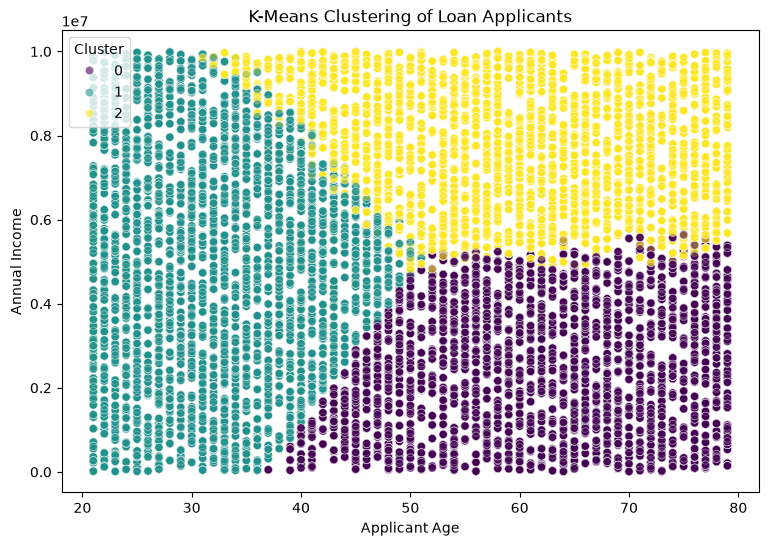

In [233]:
# Visualisation
plt.figure(figsize=(9,6))

sns.scatterplot(data=df, x = "Applicant_Age", y = "Annual_Income", hue = "Cluster", palette = "viridis", alpha = 0.6)

plt.title("K-Means Clustering of Loan Applicants")
plt.xlabel("Applicant Age")
plt.ylabel("Annual Income")
plt.show()

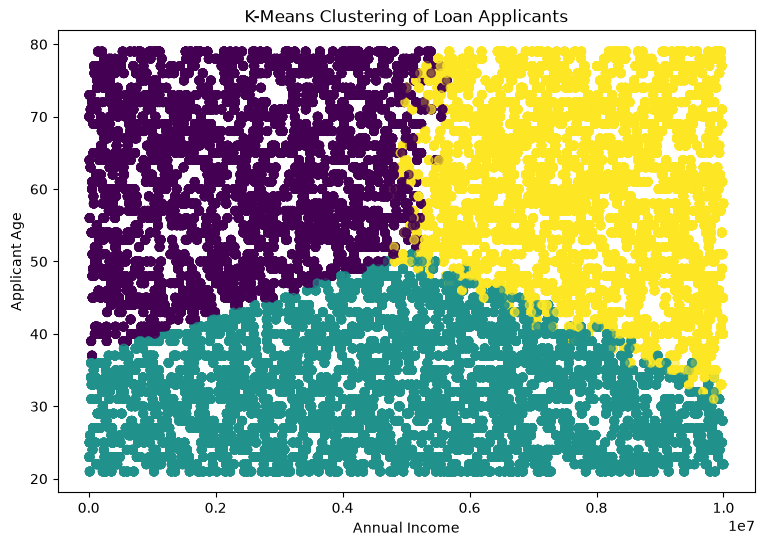

In [246]:
plt.figure(figsize=(9,6))

plt.scatter(df["Annual_Income"],df["Applicant_Age"],c=df["Cluster"],cmap = "viridis", alpha = 0.6)

plt.title("K-Means Clustering of Loan Applicants")
plt.xlabel("Annual Income")
plt.ylabel("Applicant Age")
plt.show()

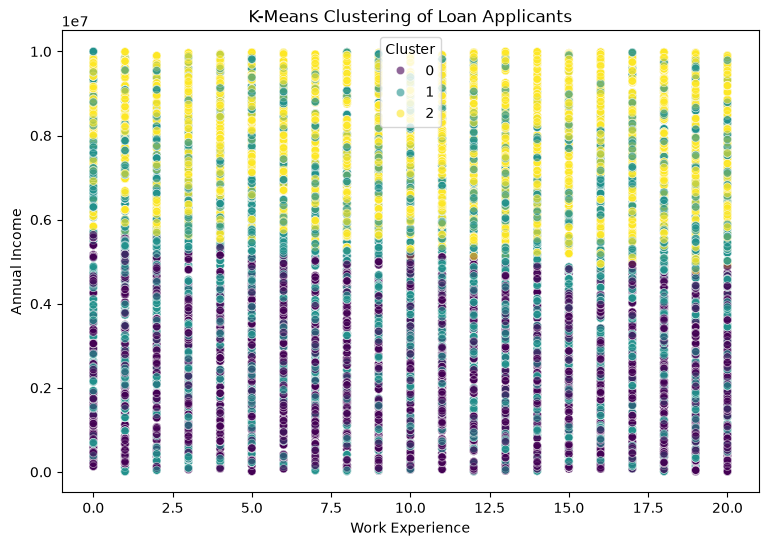

In [234]:
# Visualisation
plt.figure(figsize=(9,6))

sns.scatterplot(data=df, x = "Work_Experience", y = "Annual_Income", hue = "Cluster", palette = "viridis", alpha = 0.6)

plt.title("K-Means Clustering of Loan Applicants")
plt.xlabel("Work Experience")
plt.ylabel("Annual Income")
plt.show()

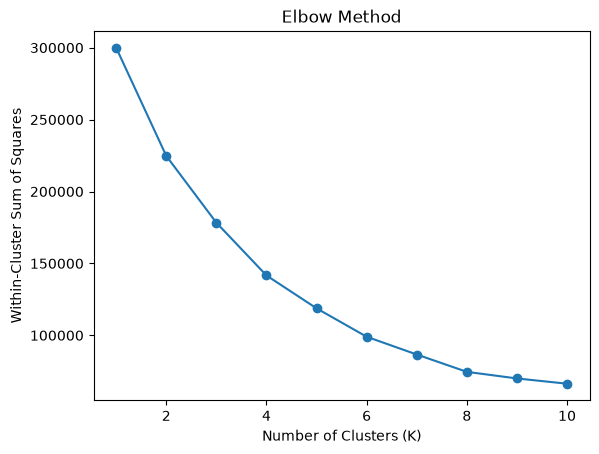

In [238]:
X = df[["Annual_Income", "Applicant_Age", "Work_Experience"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("Elbow Method")
plt.show()

In [300]:
# Now save classifiaction model and Regression model

import joblib

# Classification model
joblib.dump(rf_model,"Loan_Risk_Random_Forest_Classifier.pkl")
joblib.dump(model_balanced,"Loan_Risk_balanced_classifier.pkl")

# Regression Model
joblib.dump(lin_model,"Loan_Risk_Linear_Regression.pkl")
joblib.dump(tree_model,"Loan_Risk_Decision_Tree_Regression.pkl")
joblib.dump(rf_reg_model,"Loan_Risk_Random_Forest_Regression.pkl")
joblib.dump(ridge_model,"Loan_Risk_Ridge_Regression.pkl")

print("All model saved sucessfully")


All model saved sucessfully


In [259]:
print(X_train.columns.tolist())

['Applicant_Age', 'Work_Experience', 'Marital_Status', 'House_Ownership', 'Vehicle_Ownership(car)', 'Occupation', 'Residence_City', 'Residence_State', 'Years_in_Current_Employment', 'Years_in_Current_Residence']


# Test the model

# 1. Use balanced clasifier

In [266]:
applicant= pd.DataFrame([{
    "Annual_Income":500000,
    "Applicant_Age": 35,
    "Work_Experience": 10,
    "Marital_Status": "Married",
    "House_Ownership": "Owned",
    "Vehicle_Ownership(car)": "Yes",
    "Occupation": "Engineer",
    "Residence_City": "Pune",
    "Residence_State": "Maharashtra",
    "Years_in_Current_Employment": 5,
    "Years_in_Current_Residence": 4
}])

print(applicant)

   Annual_Income  Applicant_Age  Work_Experience Marital_Status  \
0         500000             35               10        Married   

  House_Ownership Vehicle_Ownership(car) Occupation Residence_City  \
0           Owned                    Yes   Engineer           Pune   

  Residence_State  Years_in_Current_Employment  Years_in_Current_Residence  
0     Maharashtra                            5                           4  


In [267]:
# use Loan_Risk_balanced_classifier.pkl
model_loaded = joblib.load("Loan_Risk_balanced_classifier.pkl")

print("Model Loaded Sucessfully")

print(type(model_loaded))


Model Loaded Sucessfully
<class 'sklearn.pipeline.Pipeline'>


In [287]:
print("Applicant Prediction using Balanced Classifier : \n")
prediction = model_loaded.predict(applicant)[0]
probability = model_loaded.predict_proba(applicant)[0]

print("Default Risk Probability:", round(probability[1] * 100, 2), "%")

if probability[1] >= 0.3:
    print("Prediction : Loan Default Risk = 1")
    print("Applicant is classified as loan default risk")
    
else:
    print("Prediction : Loan Default Risk = 0")
    print("Applicant is classified as non-default risk")

Applicant Prediction using Balanced Classifier : 

Default Risk Probability: 31.82 %
Prediction : Loan Default Risk = 1
Applicant is classified as loan default risk


# 2. Prediction Using Random Forest Classifier

In [289]:
model_loaded_rfc = joblib.load("Loan_Risk_Random_Forest_Classifier.pkl")

print("Applicant Prediction using Logistic Regression Classifier : \n")
prediction = model_loaded_rfc.predict(applicant)[0]
probability = model_loaded_rfc.predict_proba(applicant)[0]

print("Default Risk Probability:", round(probability[1] * 100, 2), "%")

if probability[1] >= 0.3:
    print("Prediction : Loan Default Risk = 1")
    print("Applicant is classified as loan default risk")
    
else:
    print("Prediction : Loan Default Risk = 0")
    print("Applicant is classified as non-default risk")


Applicant Prediction using Logistic Regression Classifier : 

Default Risk Probability: 15.72 %
Prediction : Loan Default Risk = 0
Applicant is classified as non-default risk


# Loan Default Risk Prediction — Project Conclusion

<h3>1. Project Overview :</h3>

The main goal of this project is to study loan applicants' information and predict whether an applicant may have difficulty repaying a loan.

The project uses a dataset containing 100,000 applicant records.

<h3>2. Key Findings :</h3>

The dataset contains 87,003 applicants in the non-default category and 12,997 applicants in the default-risk category.

I analyzed applicant details such as age, income, work experience, house ownership, vehicle ownership, and employment information.

I built models to predict loan default risk and estimate applicants' annual income.

I grouped applicants with similar characteristics to understand different types of applicants.

I also tested how the model could make a prediction for a new applicant.

<h3>3. How This Project Can Be Useful :</h3>

Banks and financial institutions can use this type of analysis to better understand applicants and identify cases that may need additional review before approving a loan.

The model's prediction should be treated as guidance, not as the only reason to approve or reject a loan.

<h3>4. Project Limitations :</h3>

The predictions may not always be correct. The results depend on the quality of the available data and how well the models perform. More testing with real-world data would be needed before using the models in an actual lending process.

<h3>5. Conclusion :</h3>

Through this project, I gained practical experience in analyzing data, preparing information for analysis, building prediction models, comparing results, and grouping applicants based on their characteristics.

This project helped me understand how data analysis and machine learning can be used to solve a real-world financial problem.